In [1]:

%pip install pandas numpy scikit-learn matplotlib seaborn joblib boto3


Note: you may need to restart the kernel to use updated packages.


In [4]:

import boto3
import pandas as pd
import numpy as np

# AWS S3 configuration
bucket_name = "heart-disease-processed-data"
file_key = "heart_cleaned_processed.csv"

# Connect to S3
s3 = boto3.client("s3")

# Read CSV from S3
response = s3.get_object(
    Bucket=bucket_name,
    Key=file_key
)

df = pd.read_csv(response["Body"])

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()


NoSuchBucket: An error occurred (NoSuchBucket) when calling the GetObject operation: The specified bucket does not exist

In [5]:

import boto3

s3 = boto3.client("s3", region_name="ap-southeast-2")

response = s3.list_buckets()

print("Available S3 buckets:")

for bucket in response["Buckets"]:
    print(bucket["Name"])


Available S3 buckets:
aws-glue-assets-297441424661-ap-southeast-2
heart-disease-processed-data-297441424661-ap-southeast-2-an
heart-disease-raw-data-2026-297441424661-ap-southeast-2-an
sagemaker-ap-southeast-2-297441424661


In [6]:

import boto3
import pandas as pd
import numpy as np

# Correct S3 configuration
bucket_name = "heart-disease-processed-data-297441424661-ap-southeast-2-an"
file_key = "heart_cleaned_processed.csv"

# Connect to S3
s3 = boto3.client("s3", region_name="ap-southeast-2")

# Read CSV
response = s3.get_object(
    Bucket=bucket_name,
    Key=file_key
)

df = pd.read_csv(response["Body"])

# Display dataset
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()


Dataset loaded successfully!
Dataset shape: (302, 23)

Column names:
['age', 'sex', 'resting_bp', 'cholesterol', 'fasting_bs_gt120', 'max_heart_rate', 'exercise_angina', 'st_depression', 'major_vessels', 'cp_0', 'cp_1', 'cp_2', 'cp_3', 'ecg_0', 'ecg_1', 'ecg_2', 'slope_0', 'slope_1', 'slope_2', 'thal_1', 'thal_2', 'thal_3', 'target']

First five rows:


,age,sex,resting_bp,cholesterol,fasting_bs_gt120,max_heart_rate,exercise_angina,st_depression,major_vessels,cp_0,...,ecg_0,ecg_1,ecg_2,slope_0,slope_1,slope_2,thal_1,thal_2,thal_3,target
0,0.9482,1,0.7628,-0.2609,1,0.0188,0,1.0822,0,0,...,1,0,0,1,0,0,1,0,0,1
1,-1.9254,1,-0.0912,0.0676,0,1.6343,0,2.1154,0,0,...,0,1,0,1,0,0,0,1,0,1
2,-1.4833,0,-0.0912,-0.8212,0,0.9793,0,0.3073,0,0,...,1,0,0,0,0,1,0,1,0,1
3,0.1746,1,-0.6606,-0.2029,0,1.2413,0,-0.2093,0,0,...,0,1,0,0,0,1,0,1,0,1
4,0.2851,0,-0.6606,2.0772,0,0.5864,1,-0.3815,0,1,...,0,1,0,0,0,1,0,1,0,1



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 302 entries, 0 to 301
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               302 non-null    float64
 1   sex               302 non-null    int64  
 2   resting_bp        302 non-null    float64
 3   cholesterol       302 non-null    float64
 4   fasting_bs_gt120  302 non-null    int64  
 5   max_heart_rate    302 non-null    float64
 6   exercise_angina   302 non-null    int64  
 7   st_depression     302 non-null    float64
 8   major_vessels     302 non-null    int64  
 9   cp_0              302 non-null    int64  
 10  cp_1              302 non-null    int64  
 11  cp_2              302 non-null    int64  
 12  cp_3              302 non-null    int64  
 13  ecg_0             302 non-null    int64  
 14  ecg_1             302 non-null    int64  
 15  ecg_2             302 non-null    int64  
 16  slope_0           302 

In [7]:
# 1. Check target values and class distribution
print("Target column values:")
print(df["target"].value_counts().sort_index())

print("\nTarget distribution (%):")
print((df["target"].value_counts(normalize=True) * 100).round(2))

# 2. Check for missing values
print("\nMissing values:")
print(df.isnull().sum().sum())

# 3. Check duplicate records
print("\nDuplicate rows:")
print(df.duplicated().sum())

# 4. Check data types
print("\nData types:")
print(df.dtypes.value_counts())

# 5. Summary statistics
print("\nSummary statistics:")
display(df.describe().round(2))

# 6. Check target values are valid
print("\nUnique target values:")
print(sorted(df["target"].unique()))

Target column values:
target
0    138
1    164
Name: count, dtype: int64

Target distribution (%):
target
1    54.3
0    45.7
Name: proportion, dtype: float64

Missing values:
0

Duplicate rows:
0

Data types:
int64      18
float64     5
Name: count, dtype: int64

Summary statistics:


,age,sex,resting_bp,cholesterol,fasting_bs_gt120,max_heart_rate,exercise_angina,st_depression,major_vessels,cp_0,...,ecg_0,ecg_1,ecg_2,slope_0,slope_1,slope_2,thal_1,thal_2,thal_3,target
count,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,...,302.00,302.0,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00
mean,0.00,0.68,0.00,-0.00,0.15,0.00,0.33,-0.00,0.67,0.47,...,0.49,0.5,0.01,0.07,0.46,0.47,0.06,0.55,0.39,0.54
std,1.00,0.47,1.00,1.00,0.36,1.00,0.47,1.00,0.94,0.50,...,0.50,0.5,0.11,0.25,0.50,0.50,0.24,0.50,0.49,0.50
min,-2.81,0.00,-2.14,-2.33,0.00,-3.43,0.00,-0.90,0.00,0.00,...,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,-0.71,0.00,-0.66,-0.69,0.00,-0.71,0.00,-0.90,0.00,0.00,...,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,0.12,1.00,-0.09,-0.12,0.00,0.13,0.00,-0.21,0.00,0.00,...,0.00,0.5,0.00,0.00,0.00,0.00,0.00,1.00,0.00,1.00
75%,0.73,1.00,0.48,0.55,0.00,0.72,1.00,0.48,1.00,1.00,...,1.00,1.0,0.00,0.00,1.00,1.00,0.00,1.00,1.00,1.00
max,2.50,1.00,3.89,6.13,1.00,2.29,1.00,4.44,3.00,1.00,...,1.00,1.0,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00



Unique target values:
[0, 1]


In [8]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop("target", axis=1)
y = df["target"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training and testing split completed!")

print("\nTraining features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training and testing split completed!

Training features shape: (241, 22)
Testing features shape: (61, 22)

Training target distribution:
target
1    131
0    110
Name: count, dtype: int64

Testing target distribution:
target
1    33
0    28
Name: count, dtype: int64


In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    class_weight="balanced"
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model training completed!")

# Make predictions on unseen test data
y_pred = rf_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=[
    "Class 0",
    "Class 1"
]))

Random Forest model training completed!

Model Accuracy: 73.77 %

Classification Report:
              precision    recall  f1-score   support

     Class 0       0.77      0.61      0.68        28
     Class 1       0.72      0.85      0.78        33

    accuracy                           0.74        61
   macro avg       0.75      0.73      0.73        61
weighted avg       0.74      0.74      0.73        61



Confusion Matrix:
[[17 11]
 [ 5 28]]


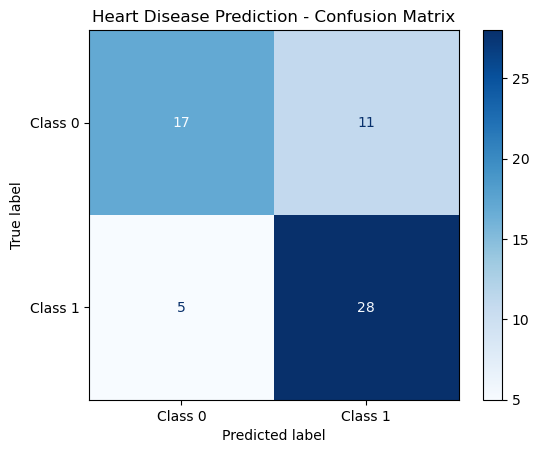

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Visualize confusion matrix
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Class 0", "Class 1"]
)

display_matrix.plot(cmap="Blues")
plt.title("Heart Disease Prediction - Confusion Matrix")
plt.show()

In [11]:
import joblib
import json
import os

print("Required libraries are ready!")

Required libraries are ready!


In [12]:
# Create a folder for model artifacts
os.makedirs("model_artifacts", exist_ok=True)

# Save the trained Random Forest model
joblib.dump(
    rf_model,
    "model_artifacts/heart_disease_model.pkl"
)

# Save the feature names in the correct order
joblib.dump(
    list(X_train.columns),
    "model_artifacts/feature_columns.pkl"
)

# Save model metadata
metadata = {
    "model_name": "Heart Disease Random Forest Classifier",
    "algorithm": "Random Forest",
    "n_estimators": 200,
    "training_records": len(X_train),
    "testing_records": len(X_test),
    "test_accuracy": round(float(accuracy), 4),
    "features_count": len(X_train.columns),
    "target_column": "target"
}

with open("model_artifacts/model_metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

print("Model artifacts saved successfully!")

Model artifacts saved successfully!


In [13]:
print("Saved model files:")

for file in os.listdir("model_artifacts"):
    print(file)

Saved model files:
heart_disease_model.pkl
feature_columns.pkl
model_metadata.json


In [14]:
import boto3
import os

bucket_name = "heart-disease-processed-data-297441424661-ap-southeast-2-an"

s3 = boto3.client("s3", region_name="ap-southeast-2")

local_folder = "model_artifacts"

for filename in os.listdir(local_folder):
    local_path = os.path.join(local_folder, filename)
    s3_key = f"model-artifacts/{filename}"

    s3.upload_file(
        local_path,
        bucket_name,
        s3_key
    )

    print(f"Uploaded: {s3_key}")

print("\nAll model artifacts uploaded successfully!")

Uploaded: model-artifacts/heart_disease_model.pkl
Uploaded: model-artifacts/feature_columns.pkl
Uploaded: model-artifacts/model_metadata.json

All model artifacts uploaded successfully!
